# IS6400 — Assignment Week 11

LI Binxiong · Student ID: 60234350

[Question 1](#q1) · [Question 2](#q2) · [Question 3](#q3)

The teacher's tutorial is retained below, followed by my answers to the three assignment questions.

In [1]:
import sys, json, platform
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('svg')
plt.rcParams.update({'figure.figsize': (12, 7), 'font.size': 12, 'svg.fonttype': 'none'})
pd.set_option('display.float_format', lambda value: f'{value:.6f}')
pd.set_option('display.max_colwidth', None)
np.random.seed(20261118)
display(HTML('<style>\nbody, .jp-Notebook {font-size:18px;line-height:1.65;}\n.jp-Notebook {max-width:1080px;margin:auto;}\n.jp-RenderedHTMLCommon p,.jp-RenderedHTMLCommon li {font-size:18px;line-height:1.65;}\n.jp-RenderedHTMLCommon table {font-size:16px;line-height:1.5;}\n.jp-RenderedHTMLCommon td {max-width:350px;white-space:normal;overflow-wrap:anywhere;}\n.jp-InputArea pre,.jp-OutputArea pre {font-size:14px;line-height:1.5;}\n.jp-RenderedHTMLCommon svg {max-width:100%;height:auto;}\n@media print {body,.jp-RenderedHTMLCommon p,.jp-RenderedHTMLCommon li {font-size:11pt;} .jp-RenderedHTMLCommon table {font-size:9pt;}}\n</style>'))

# Tutorial 11 – Model Selection

### This notebook contains all the sample code and solutions to the model assessment for model selection.

Model selection has two levels: for one model, how to choose its hyperparameters (Sections 1-3); among different models, which model to use (Section 4).
#### You will learn:

1. The use of validation dataset
2. Linear regression models with regularizations.
3. Post pruning decision tree with complexity penalty
4. Hyperparameter search with GridSearchCV
5. Choosing between models: cross-validation and hold-out

### Summary of toolbox:
1. pruning decision trees: cost_complexity_pruning_path https://scikit-learn.org/stable/auto_examples/tree/plot_cost_complexity_pruning.html

2. Support vector machine for classification: from sklearn.svm import SVC https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html
 
3. GridSearch CV: from sklearn.model_selection import GridSearchCV https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html

4. Classification report: from sklearn.metrics import classification_report https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html

# 1. Overfitting and Ridge Regression

In this section we first show that a complex model fits the training data very well but performs badly on new data (overfitting). We then use Ridge regression to penalize large coefficients, and use the validation set to choose the penalty strength.

Flow: generate data (1.1) → overfitting with a complex model (1.2) → Ridge regression (1.3) → choose the penalty α (1.4)

reference: https://www.analyticsvidhya.com/blog/2016/01/ridge-lasso-regression-python-complete-tutorial/

## 1.1 Generate the Data

Let's first generate a dataset from y = sin(x) + noise. The true pattern is a smooth curve, and the noise makes the points deviate from it. We then extend x into 15 polynomial features (x, x², ..., x¹⁵), split the data into training and validation sets, and normalize the features.

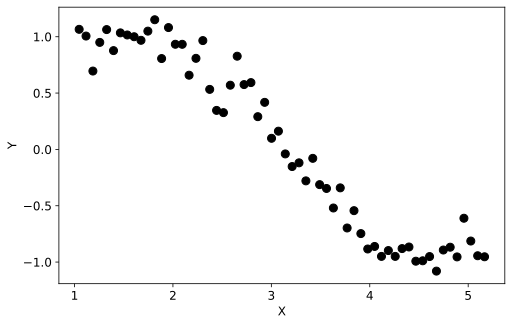

,x,y,x^2,x^3,x^4,x^5,x^6,x^7,x^8,x^9,x^10,x^11,x^12,x^13,x^14,x^15
0,1.047198,1.065763,1.096623,1.148381,1.202581,1.259340,1.318778,1.381021,1.446202,1.514459,1.585938,1.660790,1.739176,1.821260,1.907219,1.997235
1,1.117011,1.006086,1.247713,1.393709,1.556788,1.738948,1.942424,2.169709,2.423588,2.707173,3.023942,3.377775,3.773011,4.214494,4.707635,5.258479
2,1.186824,0.695374,1.408551,1.671702,1.984016,2.354677,2.794587,3.316683,3.936319,4.671717,5.544505,6.580351,7.809718,9.268760,11.000386,13.055521
3,1.256637,0.949799,1.579137,1.984402,2.493673,3.133642,3.937850,4.948448,6.218404,7.814277,9.819710,12.339811,15.506664,19.486248,24.487142,30.771450
4,1.326450,1.063496,1.759470,2.333850,3.095735,4.106339,5.446854,7.224981,9.583578,12.712139,16.862020,22.366630,29.668222,39.353420,52.200353,69.241170


In [2]:
#Importing libraries. The same will be used throughout the article.
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
%matplotlib inline
set_matplotlib_formats('svg')
from matplotlib.pylab import rcParams
plt.figure(figsize=(8,5))
#Define input array with angles from 60deg to 300deg converted to radians
x = np.array([i*np.pi/180 for i in range(60,300,4)])
np.random.seed(10)  #Setting seed for reproducibility
y = np.sin(x) + np.random.normal(0,0.15,len(x))
data = pd.DataFrame(np.column_stack([x,y]),columns=['x','y'])
plt.plot(data['x'],data['y'],".",color='black',markersize=16)
plt.xlabel('X')
plt.ylabel('Y')
plt.show()

#create new variables for x^k
for i in range(2,16):  #power of 1 is already there
    colname = 'x^%d'%i      #new var will be x_power
    data[colname] = data['x']**i
data.head()

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import MinMaxScaler,Normalizer
power=15
predictors=['x']
predictors.extend(['x^%d'%i for i in range(2,power+1)])#we extend the orignial feature x to the power of 2, 3, ..., 15
X_train, X_test, y_train, y_test = train_test_split(data[predictors], data['y'], random_state=0)

feature_scaler = MinMaxScaler()
X_train_N=feature_scaler.fit_transform(X_train) #normalize X_train
X_test_N=feature_scaler.transform(X_test) #normalize X_test using min and max of X_train

X_train=pd.DataFrame(X_train_N,columns=list(X_train))
X_test=pd.DataFrame(X_test_N,columns=list(X_test))

## 1.2 Overfitting: Polynomial Regression

A complex model can fit the training data very well, but it may have an overfitting issue: it learns the noise instead of the true pattern.

For example, we can use polynomial regression:

$$y=a0+a1*x + a2*x^2+a3*x^3+...a15*x^{15}$$

Below we check the training error, the size of the coefficients, and the validation error.

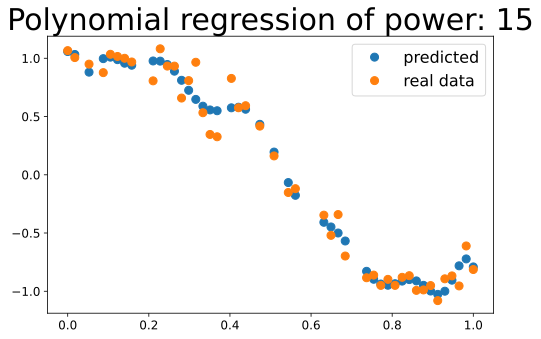

In [4]:
from sklearn.linear_model import LinearRegression

plt.figure(figsize=(8,5))

power=15

linreg = LinearRegression() #set up the model. 
#the regressor X will be normalized before regression. 
#The normalization will be done by subtracting the mean and dividing it by L2 norm.
linreg.fit(X_train,y_train)
y_pred_train = linreg.predict(X_train)

plt.plot(X_train['x'],y_pred_train,'.',markersize=16)
plt.plot(X_train['x'],y_train,'.',markersize=16)
plt.title('Polynomial regression of power: %d'%power,fontsize=30)
plt.legend(['predicted','real data'],fontsize=16)
plt.show()

Let's take a look at the training error and coefficients from this fitting.

The training error is small. But the coefficients are very large.

In [5]:
print('Training Error= %f' %mean_absolute_error(y_train, y_pred_train))
print('intercept=%f' %linreg.intercept_)
for i in range(len(linreg.coef_)):
    print('a%d=%f' %(i+1,linreg.coef_[i]))

Training Error= 0.078420
intercept=1.057908
a1=2031615.605418
a2=-36768560.102570
a3=344814633.239914
a4=-2125754111.047692
a5=9335644402.812719
a6=-30323406364.856747
a7=74292276481.272156
a8=-138540174713.093475
a9=196793348156.810089
a10=-211363749793.885498
a11=168701294680.483826
a12=-96940723811.077133
a13=37892018639.077690
a14=-9016091871.857456
a15=985240614.769836


What about validation error? The validation performance is bad.

Validation Error= 0.229992


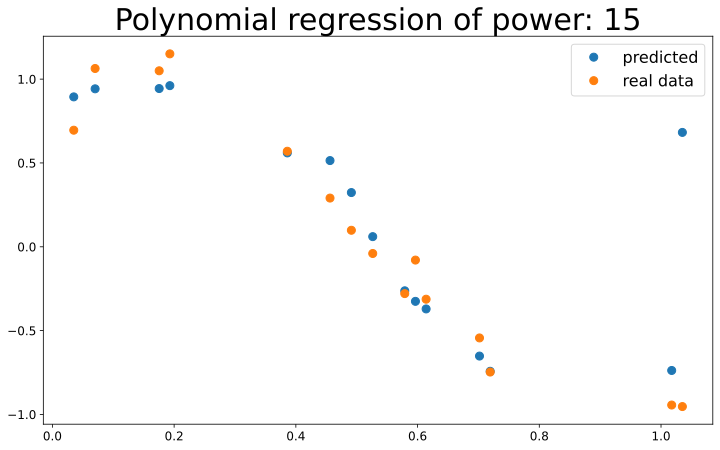

In [6]:
y_pred = linreg.predict(X_test)
print('Validation Error= %f' %mean_absolute_error(y_test, y_pred))
plt.plot(X_test['x'],y_pred,'.',markersize=16)
plt.plot(X_test['x'],y_test,'.',markersize=16)
plt.title('Polynomial regression of power: %d'%power,fontsize=30)
plt.legend(['predicted','real data'],fontsize=16)
plt.show()

## 1.3 Ridge Regression: Penalizing Large Coefficients

Ridge regression adds a penalty on the size of the coefficients, so the model cannot use very large coefficients to chase the noise.

Regression penalty: α * (sum of square of coefficients)

Here we fix the penalty α = 0.1 and compare with the polynomial regression above.

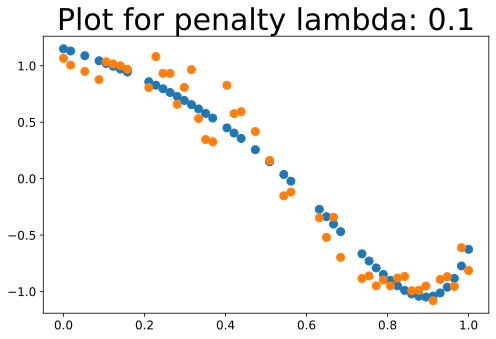

In [7]:
from sklearn.linear_model import Ridge
plt.figure(figsize=(8,5))

alpha=0.1 #the penlty term is set to be 0.1
#Fit the model
ridgereg = Ridge(alpha=alpha)
ridgereg.fit(X_train,y_train)
y_pred_train = ridgereg.predict(X_train)

    
#Check if a plot is to be made for the entered alpha
plt.plot(X_train['x'],y_pred_train,'.',markersize=16)
plt.plot(X_train['x'],y_train,'.',markersize=16)
plt.title('Plot for penalty lambda: %.3g'%alpha,fontsize=30)
plt.show()

Let's take a look at the training error and coefficients from this fitting.

The training error is larger. But the coefficients are significantly reduced. The model is reduced to a simpler form.

In [8]:
print('Training Error= %f' %mean_absolute_error(y_train, y_pred_train))
print('intercept=%f' %ridgereg.intercept_)
for i in range(len(ridgereg.coef_)):
    print('a%d=%f' %(i+1,ridgereg.coef_[i]))

Training Error= 0.126277
intercept=1.150080
a1=-0.641983
a2=-0.977411
a3=-0.936037
a4=-0.702257
a5=-0.422426
a6=-0.171054
a7=0.025460
a8=0.164427
a9=0.252661
a10=0.299650
a11=0.314658
a12=0.305680
a13=0.279223
a14=0.240404
a15=0.193162


Validation Error= 0.196034


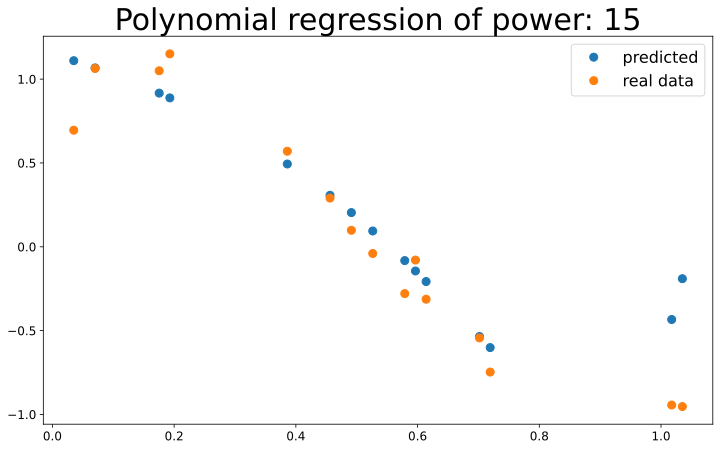

In [9]:
#The model complexity was controled. What about validation performance?
y_pred = ridgereg.predict(X_test)
print('Validation Error= %f' %mean_absolute_error(y_test, y_pred))
plt.plot(X_test['x'],y_pred,'.',markersize=16)
plt.plot(X_test['x'],y_test,'.',markersize=16)
plt.title('Polynomial regression of power: %d'%power,fontsize=30)
plt.legend(['predicted','real data'],fontsize=16)
plt.show()

## 1.4 Choose the Penalty α with the Validation Set

α controls the strength of the penalty: α = 0 means no penalty (the same as ordinary linear regression), and a larger α gives a simpler model. We try a range of α values and compare their validation errors.

In [10]:
alpha_test=[i/100 for i in range(0,20)] #search this hyperparameter from 0 to 0.19, with a step of 0.01

for alpha in alpha_test:
    ridgereg = Ridge(alpha=alpha).fit(X_train,y_train)
    y_pred = ridgereg.predict(X_test)
    print(alpha,'Validation Error= %f' %mean_absolute_error(y_test, y_pred))

0.0 Validation Error= 0.229962
0.01 Validation Error= 0.161678
0.02 Validation Error= 0.176549
0.03 Validation Error= 0.183870
0.04 Validation Error= 0.188023
0.05 Validation Error= 0.190702
0.06 Validation Error= 0.192492
0.07 Validation Error= 0.193629
0.08 Validation Error= 0.194661
0.09 Validation Error= 0.195472
0.1 Validation Error= 0.196034
0.11 Validation Error= 0.196411
0.12 Validation Error= 0.196648
0.13 Validation Error= 0.196780


0.14 Validation Error= 0.196828
0.15 Validation Error= 0.196811
0.16 Validation Error= 0.196747
0.17 Validation Error= 0.196745
0.18 Validation Error= 0.196716
0.19 Validation Error= 0.196664


### which alpha provides the best performance?

# 2. Post pruning decision trees with complexity penalty for Breast Cancer Diagnostic

[Reference](https://scikit-learn.org/stable/auto_examples/tree/plot_cost_complexity_pruning.html#sphx-glr-auto-examples-tree-plot-cost-complexity-pruning-py)

Dataset: UCI ML Breast Cancer Wisconsin (Diagnostic), downloaded from https://goo.gl/U2Uwz2

- Features are computed from a digitized image of a fine needle aspirate (FNA) of a breast mass.
- They describe characteristics of the cell nuclei present in the image.

In [11]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_breast_cancer
from sklearn.tree import DecisionTreeClassifier

We load the attributes and class label for each digitized image of a fine needle aspirate (FNA) of a breast mass. 
The detailed measurement of a cell can be found here: [data description](https://scikit-learn.org/stable/datasets/toy_dataset.html#breast-cancer-dataset)

In [12]:
cancer = load_breast_cancer()

df_feat = pd.DataFrame(cancer['data'], 
                       columns = cancer['feature_names']) 
  
# cancer column is our target 
df_target = pd.DataFrame(cancer['target'],  
                     columns =['Cancer'])

In [13]:
df_feat.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.990000,10.380000,122.800000,1001.000000,0.118400,0.277600,0.300100,0.147100,0.241900,0.078710,...,25.380000,17.330000,184.600000,2019.000000,0.162200,0.665600,0.711900,0.265400,0.460100,0.118900
1,20.570000,17.770000,132.900000,1326.000000,0.084740,0.078640,0.086900,0.070170,0.181200,0.056670,...,24.990000,23.410000,158.800000,1956.000000,0.123800,0.186600,0.241600,0.186000,0.275000,0.089020
2,19.690000,21.250000,130.000000,1203.000000,0.109600,0.159900,0.197400,0.127900,0.206900,0.059990,...,23.570000,25.530000,152.500000,1709.000000,0.144400,0.424500,0.450400,0.243000,0.361300,0.087580
3,11.420000,20.380000,77.580000,386.100000,0.142500,0.283900,0.241400,0.105200,0.259700,0.097440,...,14.910000,26.500000,98.870000,567.700000,0.209800,0.866300,0.686900,0.257500,0.663800,0.173000
4,20.290000,14.340000,135.100000,1297.000000,0.100300,0.132800,0.198000,0.104300,0.180900,0.058830,...,22.540000,16.670000,152.200000,1575.000000,0.137400,0.205000,0.400000,0.162500,0.236400,0.076780


In [14]:
df_target.head()

,Cancer
0,0
1,0
2,0
3,0
4,0


In [15]:
#randomly split the dataset. By default, the test_size=0.25
X_train, X_test, y_train, y_test = train_test_split(df_feat, np.ravel(df_target), random_state=0)  

## 2.1 Generate Candidate Penalties α

`cost_complexity_pruning_path` computes a series of effective α values on the fully grown tree: each α is the penalty at which the tree would be pruned one more step. The plot shows that a larger α gives a larger total impurity of the leaves (a coarser tree).

In [16]:
clf = DecisionTreeClassifier(random_state=0)
path = clf.cost_complexity_pruning_path(X_train, y_train) #seeking alpha
ccp_alphas, impurities = path.ccp_alphas, path.impurities #output apha and tree impurities

fig, ax = plt.subplots()
ax.plot(ccp_alphas[:-1], impurities[:-1], marker="o", drawstyle="steps-post")
ax.set_xlabel("effective alpha")
ax.set_ylabel("total impurity of leaves")
ax.set_title("Total Impurity vs effective alpha for training set")

Text(0.5, 1.0, 'Total Impurity vs effective alpha for training set')

## 2.2 Train a Tree for Each α

For each α from 2.1, we train a decision tree with `ccp_alpha=α` and store it in a list. This gives us a set of trees with different complexity.

In [17]:
clfs = [] #this list will be used to store a list of Decision Tree Models with different penalty alpha values.
for alpha in ccp_alphas:
    print('the penalty term alpha is %f' %alpha)
    clf = DecisionTreeClassifier(random_state=0, ccp_alpha=alpha) # induce a tree using the ccp_alpha value
    clf.fit(X_train, y_train)
    clfs.append(clf)

the penalty term alpha is 0.000000
the penalty term alpha is 0.002266
the penalty term alpha is 0.004647
the penalty term alpha is 0.004660
the penalty term alpha is 0.005634
the penalty term alpha is 0.007042
the penalty term alpha is 0.007842
the penalty term alpha is 0.009114
the penalty term alpha is 0.011444
the penalty term alpha is 0.018988
the penalty term alpha is 0.023142
the penalty term alpha is 0.034225
the penalty term alpha is 0.327298


### 2.2.1 Example Trees

The first tree uses the first penalty α (ccp_alphas[0] = 0), so it is the full tree without pruning. The next two plots show the tree with the 5-th α and the last α (the tree is pruned to only the root).

the first alphas is:  0.0


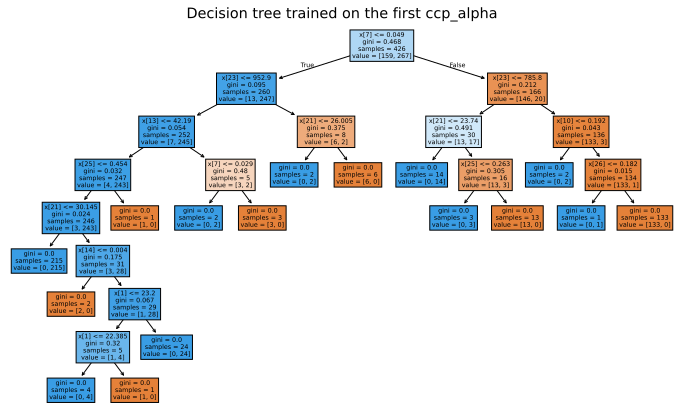

In [18]:
from sklearn.tree import plot_tree
print('the first alphas is: ', ccp_alphas[0]) #the first alpha value in the list of ccp_alphas generated.
plot_tree(clfs[0], filled=True)
plt.title("Decision tree trained on the first ccp_alpha")
plt.show()

the 5th alphas is:  0.007042253521126761


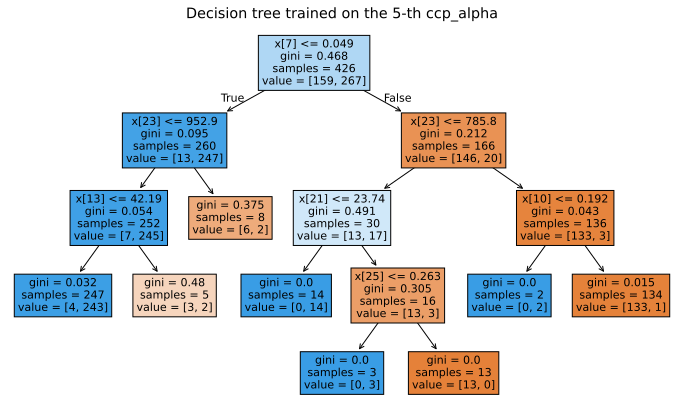

In [19]:
print('the 5th alphas is: ', ccp_alphas[5])
plot_tree(clfs[5], filled=True)
plt.title("Decision tree trained on the 5-th ccp_alpha")
plt.show()

the last alphas is:  0.3272984419327777


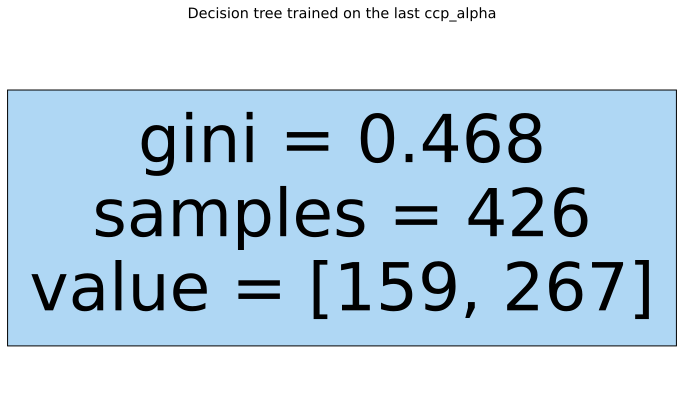

In [20]:
print('the last alphas is: ', ccp_alphas[-1])
plot_tree(clfs[-1], filled=True)
plt.title("Decision tree trained on the last ccp_alpha")
plt.show()

## 2.3 Tree Complexity vs. α

We count the number of nodes and the depth of each tree. Both decrease as α increases: a larger penalty gives a simpler tree. (The last tree, which only has the root, is excluded.)

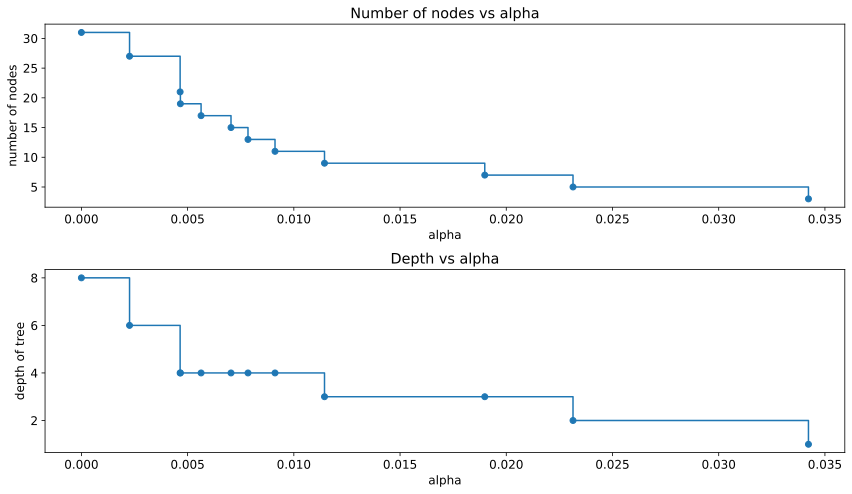

In [21]:
clfs = clfs[:-1]
ccp_alphas = ccp_alphas[:-1]

node_counts = [clf.tree_.node_count for clf in clfs]
depth = [clf.tree_.max_depth for clf in clfs]
fig, ax = plt.subplots(2, 1)
ax[0].plot(ccp_alphas, node_counts, marker="o", drawstyle="steps-post")
ax[0].set_xlabel("alpha")
ax[0].set_ylabel("number of nodes")
ax[0].set_title("Number of nodes vs alpha")
ax[1].plot(ccp_alphas, depth, marker="o", drawstyle="steps-post")
ax[1].set_xlabel("alpha")
ax[1].set_ylabel("depth of tree")
ax[1].set_title("Depth vs alpha")
fig.tight_layout()
fig

## 2.4 Conclusion

- The penalty α controls the complexity of a decision tree: a larger α prunes more branches and gives a smaller tree (fewer nodes and a smaller depth).
- This is the same idea as Ridge regression in Section 1, where a larger α gives smaller coefficients and a simpler model.
- α is a hyperparameter. A tree with α = 0 is fully grown and may overfit, while a very large α leaves only the root. To choose a good α, we need to compare the performance of the trees on validation data. Next, we learn how to search hyperparameters automatically with GridSearchCV.

# 3. Automatic Hyperparameter Search: GridSearchCV

In Section 1 we looped over α by hand and compared the validation errors ourselves. In Section 2 we generated candidate α values, but did not choose one. In this section, `GridSearchCV` does it automatically: it tries every combination of the hyperparameters we give, evaluates each one with cross-validation on the training set, and picks the best.

We use the same breast cancer training/test split as in Section 2, and the model is a support vector machine (SVC).

## 3.1 Baseline: SVC with Default Parameters

First train an SVC with the default parameters and check its performance on the test set. This is the baseline for the tuned model.

In [22]:
from sklearn.svm import SVC 
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report

In [23]:
# train the model on train set 
model = SVC() 
model.fit(X_train, y_train) 
  
# print prediction results 
predictions = model.predict(X_test) 
print(classification_report(y_test, predictions)) 

              precision    recall  f1-score   support

           0       0.98      0.85      0.91        53
           1       0.92      0.99      0.95        90

    accuracy                           0.94       143
   macro avg       0.95      0.92      0.93       143
weighted avg       0.94      0.94      0.94       143



## 3.2 GridSearchCV: Search C and gamma Automatically

- C (penalty for misclassified points) and gamma (reach of a single training point in the `rbf` kernel) control the complexity of SVC, like α in the previous sections.
- `param_grid` lists the values to try: 5 × 5 = 25 combinations. Each one is evaluated by 5-fold cross-validation on the training set (explained in Section 4), and the best one is refitted on the whole training set.

In [24]:
from sklearn.model_selection import GridSearchCV 
  
# defining hyperparameter options 
param_grid = {'C': [0.1, 1, 10, 100, 1000],  
              'gamma': [1, 0.1, 0.01, 0.001, 0.0001], 
              'kernel': ['rbf']}  
  
grid = GridSearchCV(SVC(), param_grid, refit = True, verbose = 3) 
  
# fitting the model for grid search 
grid.fit(X_train, y_train) 

Fitting 5 folds for each of 25 candidates, totalling 125 fits
[CV 1/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.628 total time=   0.0s
[CV 2/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.635 total time=   0.0s
[CV 3/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.624 total time=   0.0s
[CV 4/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.624 total time=   0.0s
[CV 5/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.624 total time=   0.0s
[CV 1/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.628 total time=   0.0s
[CV 2/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.635 total time=   0.0s
[CV 3/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.624 total time=   0.0s
[CV 4/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.624 total time=   0.0s
[CV 5/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.624 total time=   0.0s
[CV 1/5] END .....C=0.1, gamma=0.01, kernel=rbf;, score=0.628 total time=   0.0s
[CV 2/5] END .....C=0.1, gamma=0.01, kernel=rbf

[CV 4/5] END .....C=0.1, gamma=0.01, kernel=rbf;, score=0.624 total time=   0.0s
[CV 5/5] END .....C=0.1, gamma=0.01, kernel=rbf;, score=0.624 total time=   0.0s
[CV 1/5] END ....C=0.1, gamma=0.001, kernel=rbf;, score=0.628 total time=   0.0s
[CV 2/5] END ....C=0.1, gamma=0.001, kernel=rbf;, score=0.635 total time=   0.0s
[CV 3/5] END ....C=0.1, gamma=0.001, kernel=rbf;, score=0.624 total time=   0.0s
[CV 4/5] END ....C=0.1, gamma=0.001, kernel=rbf;, score=0.624 total time=   0.0s
[CV 5/5] END ....C=0.1, gamma=0.001, kernel=rbf;, score=0.624 total time=   0.0s
[CV 1/5] END ...C=0.1, gamma=0.0001, kernel=rbf;, score=0.953 total time=   0.0s
[CV 2/5] END ...C=0.1, gamma=0.0001, kernel=rbf;, score=0.894 total time=   0.0s
[CV 3/5] END ...C=0.1, gamma=0.0001, kernel=rbf;, score=0.906 total time=   0.0s
[CV 4/5] END ...C=0.1, gamma=0.0001, kernel=rbf;, score=0.906 total time=   0.0s
[CV 5/5] END ...C=0.1, gamma=0.0001, kernel=rbf;, score=0.941 total time=   0.0s
[CV 1/5] END ..........C=1, 

[CV 1/5] END ........C=1, gamma=0.1, kernel=rbf;, score=0.628 total time=   0.0s
[CV 2/5] END ........C=1, gamma=0.1, kernel=rbf;, score=0.635 total time=   0.0s
[CV 3/5] END ........C=1, gamma=0.1, kernel=rbf;, score=0.624 total time=   0.0s
[CV 4/5] END ........C=1, gamma=0.1, kernel=rbf;, score=0.624 total time=   0.0s
[CV 5/5] END ........C=1, gamma=0.1, kernel=rbf;, score=0.624 total time=   0.0s
[CV 1/5] END .......C=1, gamma=0.01, kernel=rbf;, score=0.628 total time=   0.0s
[CV 2/5] END .......C=1, gamma=0.01, kernel=rbf;, score=0.635 total time=   0.0s
[CV 3/5] END .......C=1, gamma=0.01, kernel=rbf;, score=0.624 total time=   0.0s
[CV 4/5] END .......C=1, gamma=0.01, kernel=rbf;, score=0.624 total time=   0.0s
[CV 5/5] END .......C=1, gamma=0.01, kernel=rbf;, score=0.624 total time=   0.0s
[CV 1/5] END ......C=1, gamma=0.001, kernel=rbf;, score=0.988 total time=   0.0s
[CV 2/5] END ......C=1, gamma=0.001, kernel=rbf;, score=0.894 total time=   0.0s
[CV 3/5] END ......C=1, gamm

[CV 1/5] END .....C=1, gamma=0.0001, kernel=rbf;, score=0.988 total time=   0.0s
[CV 2/5] END .....C=1, gamma=0.0001, kernel=rbf;, score=0.906 total time=   0.0s
[CV 3/5] END .....C=1, gamma=0.0001, kernel=rbf;, score=0.929 total time=   0.0s
[CV 4/5] END .....C=1, gamma=0.0001, kernel=rbf;, score=0.929 total time=   0.0s
[CV 5/5] END .....C=1, gamma=0.0001, kernel=rbf;, score=0.941 total time=   0.0s
[CV 1/5] END .........C=10, gamma=1, kernel=rbf;, score=0.628 total time=   0.0s
[CV 2/5] END .........C=10, gamma=1, kernel=rbf;, score=0.635 total time=   0.0s
[CV 3/5] END .........C=10, gamma=1, kernel=rbf;, score=0.624 total time=   0.0s
[CV 4/5] END .........C=10, gamma=1, kernel=rbf;, score=0.624 total time=   0.0s
[CV 5/5] END .........C=10, gamma=1, kernel=rbf;, score=0.624 total time=   0.0s
[CV 1/5] END .......C=10, gamma=0.1, kernel=rbf;, score=0.628 total time=   0.0s
[CV 2/5] END .......C=10, gamma=0.1, kernel=rbf;, score=0.635 total time=   0.0s
[CV 3/5] END .......C=10, ga

[CV 1/5] END ......C=10, gamma=0.01, kernel=rbf;, score=0.628 total time=   0.0s
[CV 2/5] END ......C=10, gamma=0.01, kernel=rbf;, score=0.647 total time=   0.0s
[CV 3/5] END ......C=10, gamma=0.01, kernel=rbf;, score=0.624 total time=   0.0s
[CV 4/5] END ......C=10, gamma=0.01, kernel=rbf;, score=0.635 total time=   0.0s
[CV 5/5] END ......C=10, gamma=0.01, kernel=rbf;, score=0.612 total time=   0.0s
[CV 1/5] END .....C=10, gamma=0.001, kernel=rbf;, score=0.953 total time=   0.0s
[CV 2/5] END .....C=10, gamma=0.001, kernel=rbf;, score=0.906 total time=   0.0s
[CV 3/5] END .....C=10, gamma=0.001, kernel=rbf;, score=0.882 total time=   0.0s
[CV 4/5] END .....C=10, gamma=0.001, kernel=rbf;, score=0.929 total time=   0.0s
[CV 5/5] END .....C=10, gamma=0.001, kernel=rbf;, score=0.918 total time=   0.0s
[CV 1/5] END ....C=10, gamma=0.0001, kernel=rbf;, score=0.977 total time=   0.0s
[CV 2/5] END ....C=10, gamma=0.0001, kernel=rbf;, score=0.918 total time=   0.0s
[CV 3/5] END ....C=10, gamma

[CV 2/5] END ........C=100, gamma=1, kernel=rbf;, score=0.635 total time=   0.0s
[CV 3/5] END ........C=100, gamma=1, kernel=rbf;, score=0.624 total time=   0.0s
[CV 4/5] END ........C=100, gamma=1, kernel=rbf;, score=0.624 total time=   0.0s
[CV 5/5] END ........C=100, gamma=1, kernel=rbf;, score=0.624 total time=   0.0s
[CV 1/5] END ......C=100, gamma=0.1, kernel=rbf;, score=0.628 total time=   0.0s
[CV 2/5] END ......C=100, gamma=0.1, kernel=rbf;, score=0.635 total time=   0.0s
[CV 3/5] END ......C=100, gamma=0.1, kernel=rbf;, score=0.624 total time=   0.0s
[CV 4/5] END ......C=100, gamma=0.1, kernel=rbf;, score=0.624 total time=   0.0s
[CV 5/5] END ......C=100, gamma=0.1, kernel=rbf;, score=0.624 total time=   0.0s
[CV 1/5] END .....C=100, gamma=0.01, kernel=rbf;, score=0.628 total time=   0.0s
[CV 2/5] END .....C=100, gamma=0.01, kernel=rbf;, score=0.647 total time=   0.0s
[CV 3/5] END .....C=100, gamma=0.01, kernel=rbf;, score=0.624 total time=   0.0s
[CV 4/5] END .....C=100, gam

[CV 1/5] END ....C=100, gamma=0.001, kernel=rbf;, score=0.953 total time=   0.0s
[CV 2/5] END ....C=100, gamma=0.001, kernel=rbf;, score=0.906 total time=   0.0s
[CV 3/5] END ....C=100, gamma=0.001, kernel=rbf;, score=0.882 total time=   0.0s
[CV 4/5] END ....C=100, gamma=0.001, kernel=rbf;, score=0.929 total time=   0.0s
[CV 5/5] END ....C=100, gamma=0.001, kernel=rbf;, score=0.918 total time=   0.0s
[CV 1/5] END ...C=100, gamma=0.0001, kernel=rbf;, score=0.942 total time=   0.0s
[CV 2/5] END ...C=100, gamma=0.0001, kernel=rbf;, score=0.906 total time=   0.0s
[CV 3/5] END ...C=100, gamma=0.0001, kernel=rbf;, score=0.953 total time=   0.0s
[CV 4/5] END ...C=100, gamma=0.0001, kernel=rbf;, score=0.953 total time=   0.0s
[CV 5/5] END ...C=100, gamma=0.0001, kernel=rbf;, score=0.929 total time=   0.0s
[CV 1/5] END .......C=1000, gamma=1, kernel=rbf;, score=0.628 total time=   0.0s
[CV 2/5] END .......C=1000, gamma=1, kernel=rbf;, score=0.635 total time=   0.0s
[CV 3/5] END .......C=1000, 

[CV 1/5] END .....C=1000, gamma=0.1, kernel=rbf;, score=0.628 total time=   0.0s
[CV 2/5] END .....C=1000, gamma=0.1, kernel=rbf;, score=0.635 total time=   0.0s
[CV 3/5] END .....C=1000, gamma=0.1, kernel=rbf;, score=0.624 total time=   0.0s
[CV 4/5] END .....C=1000, gamma=0.1, kernel=rbf;, score=0.624 total time=   0.0s
[CV 5/5] END .....C=1000, gamma=0.1, kernel=rbf;, score=0.624 total time=   0.0s
[CV 1/5] END ....C=1000, gamma=0.01, kernel=rbf;, score=0.628 total time=   0.0s
[CV 2/5] END ....C=1000, gamma=0.01, kernel=rbf;, score=0.647 total time=   0.0s
[CV 3/5] END ....C=1000, gamma=0.01, kernel=rbf;, score=0.624 total time=   0.0s
[CV 4/5] END ....C=1000, gamma=0.01, kernel=rbf;, score=0.635 total time=   0.0s
[CV 5/5] END ....C=1000, gamma=0.01, kernel=rbf;, score=0.612 total time=   0.0s
[CV 1/5] END ...C=1000, gamma=0.001, kernel=rbf;, score=0.953 total time=   0.0s
[CV 2/5] END ...C=1000, gamma=0.001, kernel=rbf;, score=0.906 total time=   0.0s
[CV 3/5] END ...C=1000, gamm

[CV 4/5] END ...C=1000, gamma=0.001, kernel=rbf;, score=0.929 total time=   0.0s
[CV 5/5] END ...C=1000, gamma=0.001, kernel=rbf;, score=0.918 total time=   0.0s
[CV 1/5] END ..C=1000, gamma=0.0001, kernel=rbf;, score=0.942 total time=   0.0s
[CV 2/5] END ..C=1000, gamma=0.0001, kernel=rbf;, score=0.906 total time=   0.0s
[CV 3/5] END ..C=1000, gamma=0.0001, kernel=rbf;, score=0.953 total time=   0.0s
[CV 4/5] END ..C=1000, gamma=0.0001, kernel=rbf;, score=0.941 total time=   0.0s
[CV 5/5] END ..C=1000, gamma=0.0001, kernel=rbf;, score=0.906 total time=   0.0s


GridSearchCV(estimator=SVC(),
             param_grid={'C': [0.1, 1, 10, 100, 1000],
                         'gamma': [1, 0.1, 0.01, 0.001, 0.0001],
                         'kernel': ['rbf']},
             verbose=3)

In [25]:
# print best parameter after tuning 
print(grid.best_params_) 
  
# print how our model looks after hyper-parameter tuning 
print(grid.best_estimator_) 

{'C': 1, 'gamma': 0.0001, 'kernel': 'rbf'}
SVC(C=1, gamma=0.0001)


In [26]:
grid_predictions = grid.predict(X_test) 
  
# print classification report 
print(classification_report(y_test, grid_predictions)) 

              precision    recall  f1-score   support

           0       0.92      0.92      0.92        53
           1       0.96      0.96      0.96        90

    accuracy                           0.94       143
   macro avg       0.94      0.94      0.94       143
weighted avg       0.94      0.94      0.94       143



## 3.3 Default vs. Tuned SVC

Both models are evaluated on the same test set (143 samples). The test set is only used for the final evaluation; the tuned parameters are selected by cross-validation on the training set.

| | Baseline (default SVC) | Tuned SVC (GridSearchCV) |
|---|---|---|
| Parameters | C=1, gamma='scale' | C=1, gamma=0.0001 |
| Accuracy | 0.937 | 0.944 |
| Class 0 precision / recall | 0.98 / 0.85 | 0.92 / 0.92 |
| Class 1 precision / recall | 0.92 / 0.99 | 0.96 / 0.96 |
| Macro avg F1 | 0.93 | 0.94 |

- The accuracy improves only slightly, but the tuned model is more balanced: the recall of class 0 increases from 0.85 to 0.92.
- The numbers may differ slightly with a different scikit-learn version.

# 4. Choosing Between Models

In Sections 1-3 we tuned the parameters of one model. Model selection also includes choosing which model to use: we evaluate each candidate model on data it has not been trained on, and pick the best one.

There are different ways to evaluate a model. Here we use two of them:
- Cross-validation (4.1, 4.2): the score is averaged over several train/validation splits, so it is more stable.
- Hold-out (4.3): split the data once into training and test sets.

We use stratified Cross Validation to evaluate a 3-class classification problem using the iris dataset.

Details of CV, please check documentation: 
https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-iterators 

<img src ="https://scikit-learn.org/stable/_images/sphx_glr_plot_cv_indices_003.png" width="600">

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_moons, make_circles, make_classification
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis


In [28]:
data = pd.read_csv('iris.txt',header=None)  #use tool "read_csv" to read the data in "iris.txt" file. the data is stored in "data"
data.columns = ['sepal length', 'sepal width', 'petal length', 'petal width', 'class'] #set the column names of the data table 
data.head(10) # 

,sepal length,sepal width,petal length,petal width,class
0,5.100000,3.500000,1.400000,0.200000,Iris-setosa
1,4.900000,3.000000,1.400000,0.200000,Iris-setosa
2,4.700000,3.200000,1.300000,0.200000,Iris-setosa
3,4.600000,3.100000,1.500000,0.200000,Iris-setosa
4,5.000000,3.600000,1.400000,0.200000,Iris-setosa
5,5.400000,3.900000,1.700000,0.400000,Iris-setosa
6,4.600000,3.400000,1.400000,0.300000,Iris-setosa
7,5.000000,3.400000,1.500000,0.200000,Iris-setosa
8,4.400000,2.900000,1.400000,0.200000,Iris-setosa
9,4.900000,3.100000,1.500000,0.100000,Iris-setosa


In [29]:
Y = data['class'] #this is our prediction target
X = data.drop(['class'],axis=1)

## 4.1 Cross-validation Score of Two Models

`cross_val_score` returns the score of each fold. A model with a higher score (on average) generalizes better.

In [30]:
from sklearn.model_selection import cross_val_score
clf=KNeighborsClassifier(10)
scores = cross_val_score(clf, X, Y, cv=5)
print('KNN CV Score:', scores)

KNN CV Score: [0.96666667 1.         1.         0.93333333 1.        ]


In [31]:
clf=DecisionTreeClassifier(max_depth=10)
scores = cross_val_score(clf, X, Y, cv=5)
print('DT CV Score:', scores)

DT CV Score: [0.96666667 0.96666667 0.9        0.93333333 1.        ]


## 4.2 Compare All the Models

Run the same cross-validation for 10 different classifiers and compare their scores.

In [32]:
h = 0.02  # step size in the mesh

names = [
    "Nearest Neighbors",
    "Linear SVM",
    "RBF SVM",
    "Gaussian Process",
    "Decision Tree",
    "Random Forest",
    "Neural Net",
    "AdaBoost",
    "Naive Bayes",
    "QDA",
]

classifiers = [
    KNeighborsClassifier(10),
    SVC(kernel="linear", C=0.025),
    SVC(gamma=2, C=1),
    GaussianProcessClassifier(1.0 * RBF(1.0)),
    DecisionTreeClassifier(max_depth=5),
    RandomForestClassifier(max_depth=5, n_estimators=10, max_features=1),
    MLPClassifier(alpha=1, max_iter=1000),
    AdaBoostClassifier(),
    GaussianNB(),
    QuadraticDiscriminantAnalysis(),
]

In [33]:
for i in range(len(classifiers)):
    clf=classifiers[i] #use the i-th model in the "classifiers" list
    scores = cross_val_score(clf, X, Y, cv=5)
    print('CV Score of '+ names[i], scores)

CV Score of Nearest Neighbors [0.96666667 1.         1.         0.93333333 1.        ]
CV Score of Linear SVM [0.93333333 0.96666667 0.9        0.93333333 1.        ]
CV Score of RBF SVM [0.96666667 1.         0.9        0.96666667 1.        ]


CV Score of Gaussian Process [0.96666667 1.         0.93333333 0.93333333 1.        ]
CV Score of Decision Tree [0.96666667 0.96666667 0.9        0.93333333 1.        ]
CV Score of Random Forest [0.96666667 0.96666667 0.93333333 0.9        1.        ]


CV Score of Neural Net [1.         1.         0.96666667 0.96666667 1.        ]


D:\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
D:\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
D:\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


D:\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
D:\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


CV Score of AdaBoost [0.96666667 0.93333333 0.9        0.93333333 1.        ]
CV Score of Naive Bayes [0.93333333 0.96666667 0.93333333 0.93333333 1.        ]
CV Score of QDA [1.         1.         0.96666667 0.93333333 1.        ]


## 4.3 Hold-out with Classification Report

Instead of cross-validation, we can split the data once into training and test sets, and look at the precision, recall and F1-score of each class.

In [34]:
from sklearn.metrics import classification_report # this library directly generates precision, recall, f-measure
from sklearn.model_selection import train_test_split

clf=DecisionTreeClassifier(max_depth=10)
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.33, random_state=1)
clf.fit(X_train,y_train)
y_pred=clf.predict(X_test)

print(classification_report(y_test, y_pred))

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        17
Iris-versicolor       0.95      0.95      0.95        19
 Iris-virginica       0.93      0.93      0.93        14

       accuracy                           0.96        50
      macro avg       0.96      0.96      0.96        50
   weighted avg       0.96      0.96      0.96        50



For multi-class classification, micro-average precision pools the true positives and false positives across the three classes:

$$
P_{\mathrm{micro}}=\frac{TP_1+TP_2+TP_3}{TP_1+TP_2+TP_3+FP_1+FP_2+FP_3}.
$$

Macro-average precision gives each class equal weight:

$$
P_{\mathrm{macro}}=\frac{P_1+P_2+P_3}{3}.
$$

# Summary

## 1. Overfitting and Ridge regression
- Overfitting: a complex model fits the training data well but performs badly on new data.
- Ridge regression penalizes large coefficients (`Ridge(alpha=...)`), and the validation set is used to choose α.
- `from sklearn.linear_model import LinearRegression, Ridge`
- `from sklearn.metrics import mean_absolute_error`

## 2. Post pruning decision trees
- A larger α (`ccp_alpha`) gives a smaller tree.
- `cost_complexity_pruning_path` generates the candidate α values.

## 3. Automatic hyperparameter search
- `GridSearchCV` tries all the parameter combinations (here C and gamma of `SVC`) with cross-validation and selects the best.
- `from sklearn.model_selection import GridSearchCV`

## 4. Choosing between models
- Compare different models with cross-validation (`cross_val_score`) or hold-out (`classification_report`).
- `from sklearn.model_selection import cross_val_score`
- `from sklearn.metrics import classification_report`

------------------------------------------------------------------------------------------

# Assignment Week 11

1. Use the Breast Cancer Wisconsin (Diagnostic) dataset to select the best model among Decision Trees, RandomForest, and SVC that has the minimum testing error (use the default model settings) (40 points).

2. Use the same dataset and try to use nested Cross-validation to get the optimal hyperparameters for each model, and then compare the model performance (40 points).

3. What other BDA process can you use to further improve the performance of the best models in Question 2? For example, feature selection or dimension reduction, imbalanced data sampling, etc., Please evaluate. (20 points).

<a id="q1"></a>
# Question 1 — Compare default classifiers

I use the Breast Cancer Wisconsin (Diagnostic) dataset supplied by scikit-learn: 569 observations and 30 numerical features, with 212 malignant cases (label 0) and 357 benign cases (label 1). The predictors describe cell nuclei; the target is the diagnosis class [1]. No observations or features are removed.

I follow the tutorial's hold-out split: 25% for testing, `random_state=0`, without stratification. All three classifiers receive the same unscaled training and test rows. I instantiate each classifier with its default settings. For repeatable tree and forest fits, I reset the external NumPy random seed to 20261118 immediately before each fit, leaving the estimators' `random_state=None` defaults unchanged.

Testing error is the number of incorrect predictions divided by the number of test observations:

$$
e=\frac{m}{n}=1-\mathrm{accuracy}.
$$

Here, $m$ counts incorrect predictions and $n$ counts test cases. Malignant recall counts correctly identified malignant cases divided by all malignant test cases. I report it as a secondary measure because the two kinds of mistake have different interpretations.

In [35]:
from sklearn.base import clone
plt.close('all')
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, ParameterGrid
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix

dataset = load_breast_cancer()
X_bc, y_bc = dataset.data, dataset.target
assert X_bc.shape == (569, 30) and np.isfinite(X_bc).all()
train_ids, test_ids = train_test_split(np.arange(len(y_bc)), random_state=0)
defaults = {'Decision Tree': DecisionTreeClassifier(),
            'Random Forest': RandomForestClassifier(), 'SVC': SVC()}
q1_records, q1_predictions = [], {}
for name, estimator in defaults.items():
    np.random.seed(20261118)
    estimator.fit(X_bc[train_ids], y_bc[train_ids])
    predicted = estimator.predict(X_bc[test_ids])
    q1_predictions[name] = predicted.tolist()
    wrong = int(np.sum(predicted != y_bc[test_ids]))
    q1_records.append({'Model': name, 'Wrong': wrong, 'Test n': len(test_ids),
                       'Error': wrong / len(test_ids),
                       'Accuracy': accuracy_score(y_bc[test_ids], predicted),
                       'Malignant recall': recall_score(y_bc[test_ids], predicted, pos_label=0)})
q1_table = pd.DataFrame(q1_records)
print('Training / test observations:', len(train_ids), '/', len(test_ids))
print('Test class counts [malignant, benign]:', np.bincount(y_bc[test_ids]))
display(q1_table)
q1_winner = min(q1_records, key=lambda row: row['Error'])
display(Markdown(f"{q1_winner['Model']} has the minimum observed testing error: "
                 f"{q1_winner['Wrong']}/{q1_winner['Test n']} = {q1_winner['Error']:.6f}. "
                 f"Its accuracy is {q1_winner['Accuracy']:.6f}."))

Training / test observations: 426 / 143
Test class counts [malignant, benign]: [53 90]


,Model,Wrong,Test n,Error,Accuracy,Malignant recall
0,Decision Tree,19,143,0.132867,0.867133,0.943396
1,Random Forest,4,143,0.027972,0.972028,0.981132
2,SVC,9,143,0.062937,0.937063,0.849057


Random Forest has the minimum observed testing error: 4/143 = 0.027972. Its accuracy is 0.972028.

Random Forest is selected for Question 1. Scaling SVC would change the requested default-input comparison, so I evaluate scaling separately in Question 3. The testing error here is used to choose the model family; it is therefore a selection result for this hold-out split.

<a id="q2"></a>
# Question 2 — Nested cross-validation and hyperparameters

I use five stratified outer folds, shuffled with seed 11, and three stratified inner folds, shuffled with seed 22. Stratification approximately preserves the class proportions. The same outer row indices are used for every model. In each outer fold, `GridSearchCV` selects hyperparameters using only the outer training rows. It then refits that configuration on those rows and predicts the outer test fold [2]. Accuracy is the inner selection score; testing error is the main reported comparison.

I search the grids below. `max_depth` limits the number of decisions along a tree path, `min_samples_leaf` prevents very small leaves, and the forest's `max_features` controls how many features are considered at a split. For the RBF SVC, `C` controls the penalty for margin violations and `gamma` controls how quickly similarity falls with distance. The smallest inner error identifies the best configuration within these finite grids. Question 2 keeps the raw input so that Question 3 can measure the effect of preprocessing.

In [36]:
model_specs = {
    'Decision Tree': (Pipeline([('model', DecisionTreeClassifier(random_state=0))]),
                      {'model__max_depth': [3, 5, None], 'model__min_samples_leaf': [1, 3]}),
    'Random Forest': (Pipeline([('model', RandomForestClassifier(random_state=0))]),
                      {'model__max_depth': [5, None], 'model__min_samples_leaf': [1, 3],
                       'model__max_features': ['sqrt', 0.5]}),
    'SVC': (Pipeline([('model', SVC())]),
            {'model__C': [0.1, 1, 10, 100], 'model__gamma': ['scale', 0.0001, 0.001]})
}
outer_splits = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=11).split(X_bc, y_bc))
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=22)
grid_rows = [{'Model': name, 'Candidates': len(ParameterGrid(grid)), 'Grid': str(grid)}
             for name, (_, grid) in model_specs.items()]
display(pd.DataFrame(grid_rows))
print('Outer train / test sizes:', [(len(tr), len(te)) for tr, te in outer_splits])

,Model,Candidates,Grid
0,Decision Tree,6,"{'model__max_depth': [3, 5, None], 'model__min_samples_leaf': [1, 3]}"
1,Random Forest,8,"{'model__max_depth': [5, None], 'model__min_samples_leaf': [1, 3], 'model__max_features': ['sqrt', 0.5]}"
2,SVC,12,"{'model__C': [0.1, 1, 10, 100], 'model__gamma': ['scale', 0.0001, 0.001]}"


Outer train / test sizes: [(455, 114), (455, 114), (455, 114), (455, 114), (456, 113)]


For one outer iteration, the available training rows are divided into three inner parts. Each candidate is fitted on two parts and evaluated on the third, rotating three times. The candidate with the highest mean inner accuracy is refitted on all outer training rows. Only then is the outer test fold predicted. The whole search starts again for the next outer fold.

The function below stores each fold's selected configuration, outer predictions, and confusion matrix. It also records how many features or components remain when a preprocessing step is present. Thus the same evaluation code can be used for Question 3.

In [37]:
def evaluate_nested(label, pipeline, grid):
    records = []
    oof_predictions = np.full(len(y_bc), -1, dtype=int)
    for fold, (train, test) in enumerate(outer_splits, start=1):
        assert not np.intersect1d(train, test).size
        search = GridSearchCV(clone(pipeline), grid, cv=inner_cv, scoring='accuracy',
                              refit=True, n_jobs=1, error_score='raise')
        search.fit(X_bc[train], y_bc[train])
        predicted = search.predict(X_bc[test])
        oof_predictions[test] = predicted
        fitted = search.best_estimator_.named_steps
        feature_count = (int(fitted['select'].get_support().sum()) if 'select' in fitted
                         else int(fitted['pca'].n_components_) if 'pca' in fitted else X_bc.shape[1])
        wrong = int(np.sum(predicted != y_bc[test]))
        records.append({'Fold': fold, 'Train n': len(train), 'Test n': len(test), 'Wrong': wrong,
                        'Error': wrong / len(test), 'Accuracy': accuracy_score(y_bc[test], predicted),
                        'Malignant recall': recall_score(y_bc[test], predicted, pos_label=0),
                        'Inner accuracy': float(search.best_score_), 'Parameters': search.best_params_,
                        'Features/components': feature_count,
                        'Confusion': confusion_matrix(y_bc[test], predicted, labels=[0, 1]).tolist()})
    assert (oof_predictions >= 0).all()
    errors = np.array([row['Error'] for row in records])
    return {'label': label, 'folds': records, 'oof': oof_predictions.tolist(),
            'mean_error': float(errors.mean()), 'sd_error': float(errors.std(ddof=1)),
            'pooled_error': float(np.mean(oof_predictions != y_bc)),
            'malignant_recall': float(recall_score(y_bc, oof_predictions, pos_label=0))}

q2_results = {name: evaluate_nested(name, pipe, grid)
              for name, (pipe, grid) in model_specs.items()}

def summary_frame(results):
    return pd.DataFrame([{'Pipeline': name, 'Mean error': r['mean_error'],
                          'Fold SD': r['sd_error'], 'Pooled error': r['pooled_error'],
                          'Malignant recall': r['malignant_recall']}
                         for name, r in results.items()])

display(summary_frame(q2_results))
q2_winner = min(q2_results, key=lambda name: q2_results[name]['mean_error'])
display(Markdown(f"{q2_winner} has the lowest mean outer error, "
                 f"{q2_results[q2_winner]['mean_error']:.6f}, "
                 f"with a fold standard deviation of {q2_results[q2_winner]['sd_error']:.6f}."))

,Pipeline,Mean error,Fold SD,Pooled error,Malignant recall
0,Decision Tree,0.068576,0.023699,0.068541,0.905660
1,Random Forest,0.042136,0.018967,0.042179,0.933962
2,SVC,0.063236,0.015573,0.063269,0.882075


Random Forest has the lowest mean outer error, 0.042136, with a fold standard deviation of 0.018967.

Each row above summarizes five outer evaluations. “Mean error” gives each fold equal weight. “Pooled error” counts all errors among the 569 out-of-fold predictions, so a fold with 114 observations weighs slightly more than the fold with 113. “Fold SD” is the sample standard deviation across the five fold errors, using a denominator of four; it describes split variation rather than a confidence interval. Malignant recall is pooled across all out-of-fold predictions.

The next tables show each selected configuration and its actual outer result. Inner accuracy is used for selection; outer error is used for evaluation.

In [38]:
for name, result in q2_results.items():
    display(Markdown('## ' + name + ' — outer folds'))
    fold_table = pd.DataFrame(result['folds'])
    display(fold_table[['Fold', 'Test n', 'Wrong', 'Error', 'Inner accuracy']])
    display(fold_table[['Fold', 'Parameters']])

## Decision Tree — outer folds

,Fold,Test n,Wrong,Error,Inner accuracy
0,1,114,10,0.087719,0.918671
1,2,114,6,0.052632,0.936244
2,3,114,9,0.078947,0.931887
3,4,114,4,0.035088,0.936244
4,5,113,10,0.088496,0.916667


,Fold,Parameters
0,1,"{'model__max_depth': 5, 'model__min_samples_leaf': 3}"
1,2,"{'model__max_depth': 5, 'model__min_samples_leaf': 1}"
2,3,"{'model__max_depth': 5, 'model__min_samples_leaf': 3}"
3,4,"{'model__max_depth': 5, 'model__min_samples_leaf': 3}"
4,5,"{'model__max_depth': 5, 'model__min_samples_leaf': 3}"


## Random Forest — outer folds

,Fold,Test n,Wrong,Error,Inner accuracy
0,1,114,6,0.052632,0.964854
1,2,114,6,0.052632,0.951624
2,3,114,7,0.061404,0.945045
3,4,114,3,0.026316,0.949445
4,5,113,2,0.017699,0.949561


,Fold,Parameters
0,1,"{'model__max_depth': 5, 'model__max_features': 0.5, 'model__min_samples_leaf': 1}"
1,2,"{'model__max_depth': 5, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1}"
2,3,"{'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 1}"
3,4,"{'model__max_depth': 5, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1}"
4,5,"{'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1}"


## SVC — outer folds

,Fold,Test n,Wrong,Error,Inner accuracy
0,1,114,7,0.061404,0.942823
1,2,114,9,0.078947,0.940659
2,3,114,6,0.052632,0.938524
3,4,114,9,0.078947,0.945088
4,5,113,5,0.044248,0.938596


,Fold,Parameters
0,1,"{'model__C': 10, 'model__gamma': 0.0001}"
1,2,"{'model__C': 100, 'model__gamma': 'scale'}"
2,3,"{'model__C': 10, 'model__gamma': 0.0001}"
3,4,"{'model__C': 10, 'model__gamma': 0.0001}"
4,5,"{'model__C': 1, 'model__gamma': 0.0001}"


After the outer comparison, I also run the same inner search on all 569 observations to obtain one fitted configuration per family for future predictions. These configurations need not equal every fold's choice. Their selection scores are not additional test results.

In [39]:
final_configurations = []
for name, (pipe, grid) in model_specs.items():
    search = GridSearchCV(clone(pipe), grid, cv=inner_cv, scoring='accuracy',
                          refit=True, n_jobs=1, error_score='raise')
    search.fit(X_bc, y_bc)
    final_configurations.append({'Model': name, 'Full-data selected parameters': search.best_params_})
display(pd.DataFrame(final_configurations))

,Model,Full-data selected parameters
0,Decision Tree,"{'model__max_depth': None, 'model__min_samples_leaf': 1}"
1,Random Forest,"{'model__max_depth': 5, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1}"
2,SVC,"{'model__C': 100, 'model__gamma': 0.0001}"


<a id="q3"></a>
# Question 3 — Evaluate additional BDA processing

I evaluate feature selection for the Question 2 Random Forest candidate and investigate whether scaling changes the SVC comparison. To separate the effects, I compare scaled SVC with both a feature-selection version and a PCA version, using the same outer folds and SVC grid.

`SelectKBest(f_classif)` ranks features using the difference between the two class means relative to variation within each class, retaining 10, 20, or all 30 features. Standardization subtracts the training mean and divides by the training standard deviation [3]. For example, training values 2 and 4 have mean 3 and population standard deviation 1, so a validation value 6 becomes 3. PCA creates new axes as linear combinations of the standardized features, keeping enough components to exceed a chosen fraction of training variance [4]. Variance retention does not directly optimize classification accuracy.

All transformations are inside `Pipeline`. Feature rankings, scaling statistics, and PCA directions are refitted on each inner training fold; the outer test fold is transformed using the fitted outer-training pipeline. The preprocessing choices and model parameters are searched together.

In [40]:
rf_pipe, rf_grid = model_specs['Random Forest']
svc_pipe, svc_grid = model_specs['SVC']
q3_specs = {
    'RF + selection': (Pipeline([('select', SelectKBest(f_classif)),
                                ('model', RandomForestClassifier(random_state=0))]),
                       dict(rf_grid, select__k=[10, 20, 'all'])),
    'SVC + scaling': (Pipeline([('scale', StandardScaler()), ('model', SVC())]), svc_grid),
    'SVC + selection + scaling': (Pipeline([('select', SelectKBest(f_classif)),
                                           ('scale', StandardScaler()), ('model', SVC())]),
                                  dict(svc_grid, select__k=[10, 20, 'all'])),
    'SVC + scaling + PCA': (Pipeline([('scale', StandardScaler()),
                                     ('pca', PCA(svd_solver='full')), ('model', SVC())]),
                            dict(svc_grid, pca__n_components=[0.90, 0.95, 0.99]))
}
q3_results = {name: evaluate_nested(name, pipe, grid)
              for name, (pipe, grid) in q3_specs.items()}
all_results = {**q2_results, **q3_results}
display(summary_frame(all_results))
for name, result in q3_results.items():
    display(Markdown('## ' + name + ' — selected processing'))
    display(pd.DataFrame(result['folds'])[['Fold', 'Error', 'Features/components', 'Parameters']])

,Pipeline,Mean error,Fold SD,Pooled error,Malignant recall
0,Decision Tree,0.068576,0.023699,0.068541,0.905660
1,Random Forest,0.042136,0.018967,0.042179,0.933962
2,SVC,0.063236,0.015573,0.063269,0.882075
3,RF + selection,0.035119,0.013821,0.035149,0.938679
4,SVC + scaling,0.022838,0.009981,0.022847,0.952830
5,SVC + selection + scaling,0.021084,0.007829,0.021090,0.957547
6,SVC + scaling + PCA,0.026362,0.010744,0.026362,0.948113


## RF + selection — selected processing

,Fold,Error,Features/components,Parameters
0,1,0.052632,30,"{'model__max_depth': 5, 'model__max_features': 0.5, 'model__min_samples_leaf': 1, 'select__k': 'all'}"
1,2,0.035088,20,"{'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'select__k': 20}"
2,3,0.043860,20,"{'model__max_depth': 5, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'select__k': 20}"
3,4,0.026316,20,"{'model__max_depth': 5, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'select__k': 20}"
4,5,0.017699,20,"{'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 1, 'select__k': 20}"


## SVC + scaling — selected processing

,Fold,Error,Features/components,Parameters
0,1,0.026316,30,"{'model__C': 100, 'model__gamma': 0.001}"
1,2,0.026316,30,"{'model__C': 100, 'model__gamma': 0.001}"
2,3,0.035088,30,"{'model__C': 100, 'model__gamma': 0.001}"
3,4,0.008772,30,"{'model__C': 10, 'model__gamma': 0.001}"
4,5,0.017699,30,"{'model__C': 100, 'model__gamma': 0.001}"


## SVC + selection + scaling — selected processing

,Fold,Error,Features/components,Parameters
0,1,0.026316,20,"{'model__C': 100, 'model__gamma': 0.001, 'select__k': 20}"
1,2,0.026316,20,"{'model__C': 100, 'model__gamma': 0.001, 'select__k': 20}"
2,3,0.026316,20,"{'model__C': 100, 'model__gamma': 0.001, 'select__k': 20}"
3,4,0.008772,20,"{'model__C': 100, 'model__gamma': 0.001, 'select__k': 20}"
4,5,0.017699,30,"{'model__C': 100, 'model__gamma': 0.001, 'select__k': 'all'}"


## SVC + scaling + PCA — selected processing

,Fold,Error,Features/components,Parameters
0,1,0.026316,17,"{'model__C': 100, 'model__gamma': 0.001, 'pca__n_components': 0.99}"
1,2,0.035088,10,"{'model__C': 100, 'model__gamma': 0.001, 'pca__n_components': 0.95}"
2,3,0.035088,10,"{'model__C': 100, 'model__gamma': 0.001, 'pca__n_components': 0.95}"
3,4,0.008772,10,"{'model__C': 100, 'model__gamma': 0.001, 'pca__n_components': 0.95}"
4,5,0.026549,16,"{'model__C': 100, 'model__gamma': 0.001, 'pca__n_components': 0.99}"


In [41]:
rf_before, rf_after = q2_results['Random Forest'], q3_results['RF + selection']
svc_raw, svc_scaled = q2_results['SVC'], q3_results['SVC + scaling']
svc_selected = q3_results['SVC + selection + scaling']
svc_pca = q3_results['SVC + scaling + PCA']
rf_change = rf_after['mean_error'] - rf_before['mean_error']
best_pipeline = min(all_results, key=lambda name: all_results[name]['mean_error'])
display(Markdown(
    f"Feature selection changes Random Forest's mean error from {rf_before['mean_error']:.6f} "
    f"to {rf_after['mean_error']:.6f}, a change of {rf_change:+.6f} "
    f"({100 * rf_change:+.6f} percentage points). "
    + ('I would adopt this candidate over raw Random Forest in this comparison.' if rf_change < 0
       else 'This evaluation does not support adopting feature selection as an improvement for Random Forest.')
    + f"\n\nScaling SVC changes its mean error from {svc_raw['mean_error']:.6f} "
      f"to {svc_scaled['mean_error']:.6f}. Adding feature selection gives "
      f"{svc_selected['mean_error']:.6f}, while adding PCA gives {svc_pca['mean_error']:.6f}. "
      f"The lowest mean error among the evaluated pipelines is "
      f"{all_results[best_pipeline]['mean_error']:.6f} for {best_pipeline}."))

Feature selection changes Random Forest's mean error from 0.042136 to 0.035119, a change of -0.007018 (-0.701754 percentage points). I would adopt this candidate over raw Random Forest in this comparison.

Scaling SVC changes its mean error from 0.063236 to 0.022838. Adding feature selection gives 0.021084, while adding PCA gives 0.026362. The lowest mean error among the evaluated pipelines is 0.021084 for SVC + selection + scaling.

## Additional evaluation — error types and paired fold changes

Mean error treats a missed malignant case and a benign case predicted malignant equally. I therefore inspect both error types, and compare preprocessing changes fold by fold. The paired comparison holds the outer observations fixed and helps identify whether an average improvement occurs throughout the splits or only in a few folds.

,Pipeline,Malignant missed,Benign called malignant,Malignant recall
0,Decision Tree,20,19,0.905660
1,Random Forest,14,10,0.933962
2,SVC,25,11,0.882075
3,RF + selection,13,7,0.938679
4,SVC + scaling,10,3,0.952830
5,SVC + selection + scaling,9,3,0.957547
6,SVC + scaling + PCA,11,4,0.948113


,Fold,RF selection minus raw,SVC scaling minus raw,SVC selection minus scaling,SVC PCA minus scaling
0,1,0.000000,-0.035088,0.000000,0.000000
1,2,-0.017544,-0.052632,0.000000,0.008772
2,3,-0.017544,-0.017544,-0.008772,0.000000
3,4,0.000000,-0.070175,0.000000,0.000000
4,5,0.000000,-0.026549,0.000000,0.008850


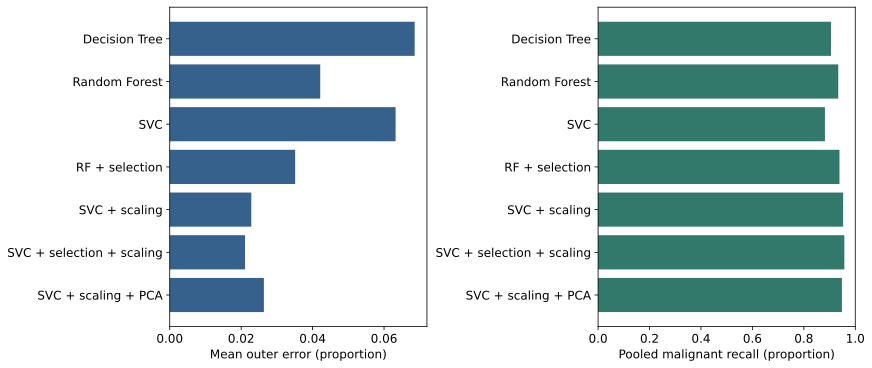

In [42]:
error_types = []
for name, result in all_results.items():
    cm = confusion_matrix(y_bc, result['oof'], labels=[0, 1])
    error_types.append({'Pipeline': name, 'Malignant missed': int(cm[0, 1]),
                        'Benign called malignant': int(cm[1, 0]),
                        'Malignant recall': result['malignant_recall']})
display(pd.DataFrame(error_types))
paired = pd.DataFrame({'Fold': range(1, 6),
    'RF selection minus raw': [a['Error'] - b['Error'] for a, b in zip(rf_after['folds'], rf_before['folds'])],
    'SVC scaling minus raw': [a['Error'] - b['Error'] for a, b in zip(svc_scaled['folds'], svc_raw['folds'])],
    'SVC selection minus scaling': [a['Error'] - b['Error'] for a, b in zip(svc_selected['folds'], svc_scaled['folds'])],
    'SVC PCA minus scaling': [a['Error'] - b['Error'] for a, b in zip(svc_pca['folds'], svc_scaled['folds'])]})
display(paired)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
labels = list(all_results)
positions = np.arange(len(labels))
axes[0].barh(positions, [all_results[n]['mean_error'] for n in labels], color='#35618c')
axes[0].set_yticks(positions, labels)
axes[0].invert_yaxis()
axes[0].set_xlabel('Mean outer error (proportion)')
axes[1].barh(positions, [all_results[n]['malignant_recall'] for n in labels], color='#32796c')
axes[1].set_yticks(positions, labels)
axes[1].invert_yaxis()
axes[1].set_xlim(0, 1)
axes[1].set_xlabel('Pooled malignant recall (proportion)')
plt.show()

Figure A1 compares error (lower is better) with malignant recall (higher is better). The recall denominator is 212 malignant observations. The tables distinguish false negatives for malignant cases from false alarms among benign cases.

The classes are moderately uneven (212 versus 357). I preserve their observed proportions rather than introduce resampling without a specific error-cost objective. If missed malignant cases were the selection priority, I would define that objective before rerunning model selection. Scaling, feature removal, and PCA are evaluated here; synthetic oversampling is not claimed as a tested improvement.

The outer scores have now been compared across model families and preprocessing choices, so they support a development comparison of these candidates. A final selected pipeline would need new data or a further evaluation layer for an independent final estimate. Five overlapping training folds do not provide five independent experiments, and the fold differences are not a significance test.

## References

1. scikit-learn 1.5, [Breast Cancer Wisconsin (Diagnostic) dataset](https://scikit-learn.org/1.5/modules/generated/sklearn.datasets.load_breast_cancer.html).
2. scikit-learn 1.5, [Nested versus non-nested cross-validation](https://scikit-learn.org/1.5/auto_examples/model_selection/plot_nested_cross_validation_iris.html).
3. scikit-learn 1.5, [StandardScaler](https://scikit-learn.org/1.5/modules/generated/sklearn.preprocessing.StandardScaler.html).
4. scikit-learn 1.5, [PCA](https://scikit-learn.org/1.5/modules/generated/sklearn.decomposition.PCA.html).

In [43]:
# Record the computational environment and numerical results.
answer_results = {'environment': {'Python': platform.python_version(), 'NumPy': np.__version__,
                                  'pandas': pd.__version__, 'scikit-learn': sklearn.__version__},
                  'q1': q1_records, 'q1_predictions': q1_predictions,
                  'q1_test_ids': test_ids.tolist(), 'q1_train_ids': train_ids.tolist(),
                  'outer_test_ids': [te.tolist() for _, te in outer_splits],
                  'q2': q2_results, 'q2_final_configurations': final_configurations,
                  'q3': q3_results}
print(json.dumps(answer_results['environment'], indent=2))

{
  "Python": "3.12.3",
  "NumPy": "1.26.4",
  "pandas": "2.3.3",
  "scikit-learn": "1.5.1"
}


I used OpenAI Codex to assist with this assignment.